### Initialization
Add the Surrogate Modeling module and setup the notebook

In [1]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from SurrogateModels import cokriging, kriging

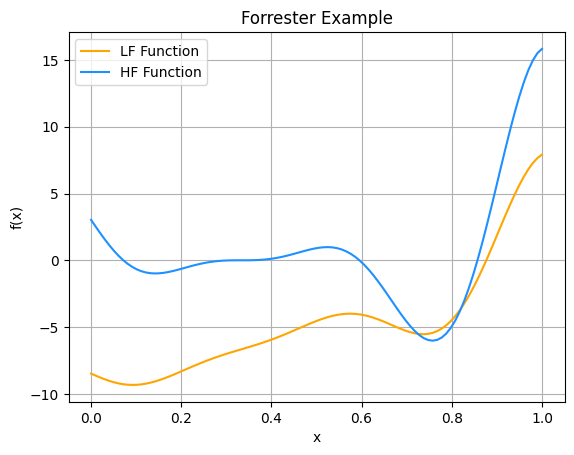

In [2]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.ForresterExample()
mf_example.plot_functions(name = mf_example.name)
plt.grid()
plt.legend()
plt.show()

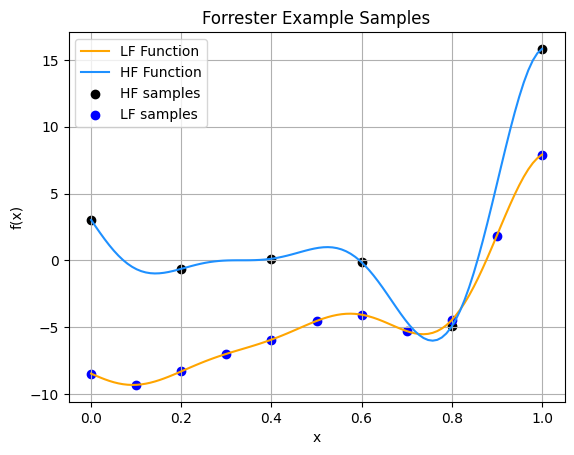

In [3]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 11 # number of low fidelity points
n_hf = 6 # number of high fidelity points
n_test = 40 # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

X_lf = np.linspace(xmin,xmax,n_lf,dtype=np.float32).reshape(-1,1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin,xmax,n_hf,dtype=np.float32).reshape(-1,1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin,xmax,n_test,dtype=np.float32).reshape(-1,1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions(name = plot_name)

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.legend()
plt.show()

In [4]:
forrester_kriging_model = kriging.Kriging(X_lf,y_lf)

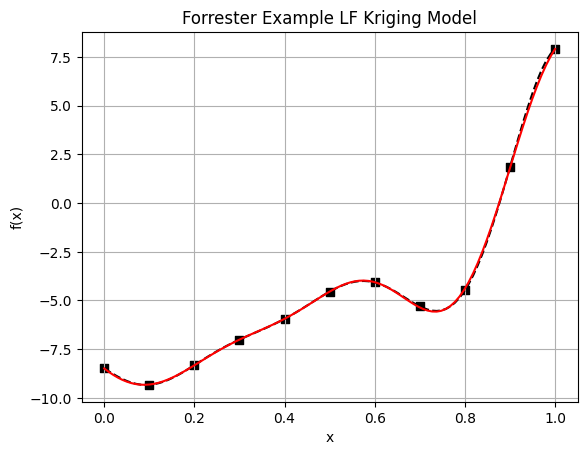

In [5]:
plot_name = mf_example.name + " LF Kriging Model"

X_check = np.linspace(0, 1.0, 300, endpoint=True,dtype=np.float32).reshape(-1,1)

ax = mf_example.plot_low_fidelity(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed"
)
ax = forrester_kriging_model.plot_data(
    name=plot_name,
    color="black",
    label="LF",
    marker="s",
    ax = ax
)
forrester_kriging_model.plot_model(
    mf_example.bounds, name=plot_name, color="red", label="Kriging", linestyle="solid",ax=ax
)
plt.grid()
plt.show()

In [6]:
forrester_cokriging_model = cokriging.CoKriging(X_lf,y_lf,X_hf,y_hf)

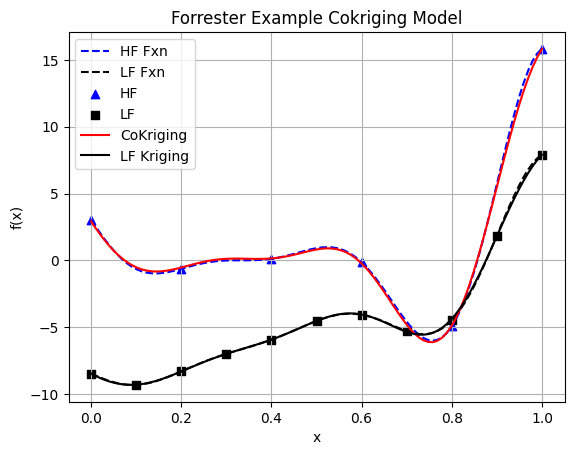

In [7]:
plot_name = mf_example.name + " Cokriging Model"

ax = mf_example.plot_high_fidelity(
    name=plot_name, color="blue", label="HF Fxn", linestyle="dashed"
)
ax = mf_example.plot_low_fidelity(
    name=plot_name, color="black", label="LF Fxn", linestyle="dashed", ax=ax
)
ax = forrester_cokriging_model.plot_data(
    name=plot_name,
    color_lf="black",
    color_hf="blue",
    label_hf="HF",
    label_lf="LF",
    marker_hf="^",
    marker_lf="s",
    ax = ax
)
ax = forrester_cokriging_model.plot_model(
    mf_example.bounds, name=plot_name, color="red", label="CoKriging", linestyle="solid",ax=ax
)
ax = forrester_cokriging_model.kriging_lf.plot_model(
    mf_example.bounds, name=plot_name, color="black", label="LF Kriging", linestyle="solid",ax=ax
)
plt.grid()
plt.legend()
plt.show()

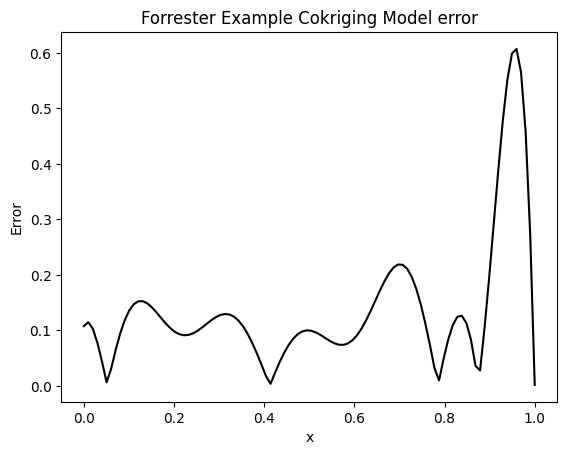

In [8]:
plot_name = plot_name + " error"

forrester_cokriging_model.plot_rms_error(
    mf_example.bounds, mf_example.high_fidelity, name=plot_name
)
plt.show()

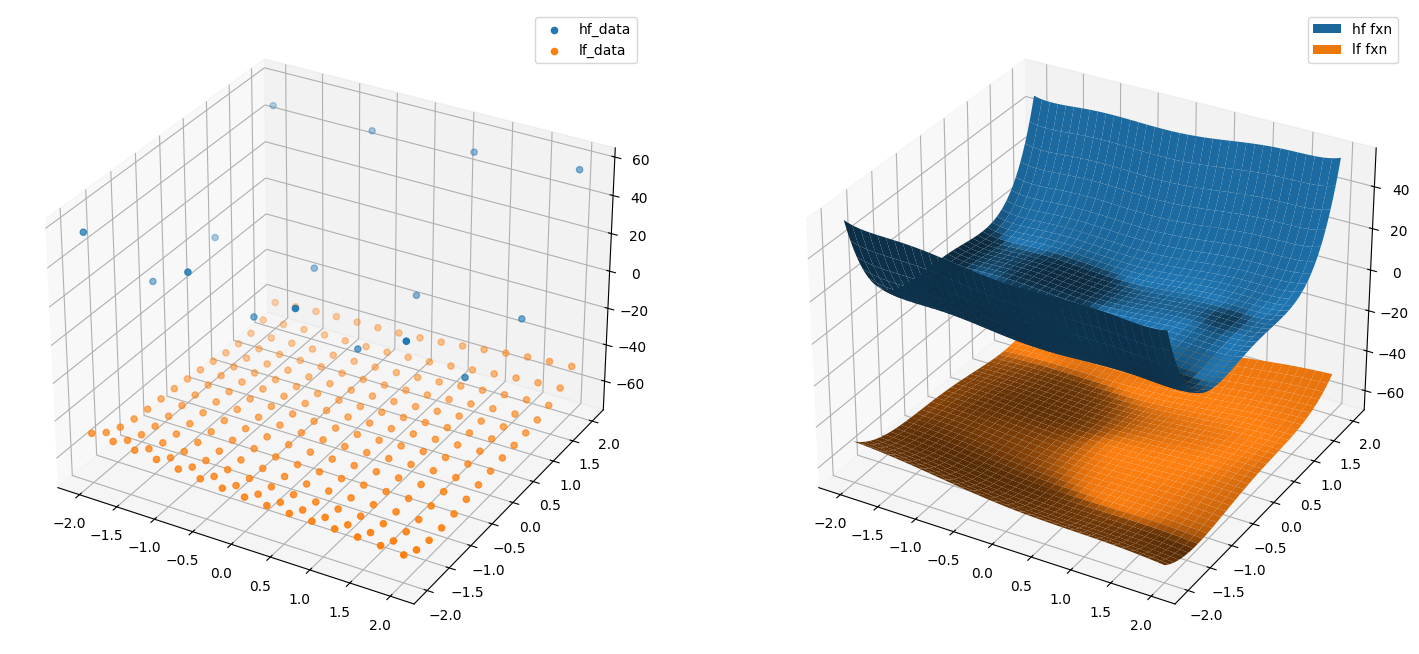

In [9]:
import multi_fidelity_functions as mff
import matplotlib.pyplot as plt
from SurrogateModels import cokriging, model

n_hf = 4
n_lf = 15
n_samp = 75

mf_2d = mff.ZhangExample6()

bounds = mf_2d.bounds
x1min = bounds[0][0]
x1max = bounds[0][1]
x2min = bounds[1][0]
x2max = bounds[1][1]

x_hf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_hf)
x_lf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_lf)
y_hf = mf_2d.high_fidelity(x_hf)
y_lf = mf_2d.low_fidelity(x_lf)

# take samples for plotting ground truth function
x_samp = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = mf_2d.high_fidelity(x_samp)
y_samp_lf = mf_2d.low_fidelity(x_samp)

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(121, projection="3d")

sc = ax.scatter(x_hf[:, 0], x_hf[:, 1],y_hf[:,0], label="hf_data")
sc = ax.scatter(x_lf[:, 0], x_lf[:, 1],y_lf[:,0], label="lf_data")
ax.legend()

#Plot the actual surfaces of the lf and hf functions

X1, X2 = model.Model.generate_grid(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = y_samp_hf.reshape(n_samp,n_samp)
y_samp_lf = y_samp_lf.reshape(n_samp,n_samp)

ax = fig.add_subplot(122, projection="3d")
ax.plot_surface(X1, X2, y_samp_hf,label="hf fxn")
ax.plot_surface(X1, X2, y_samp_lf,label="lf fxn")
ax.legend()

plt.show()

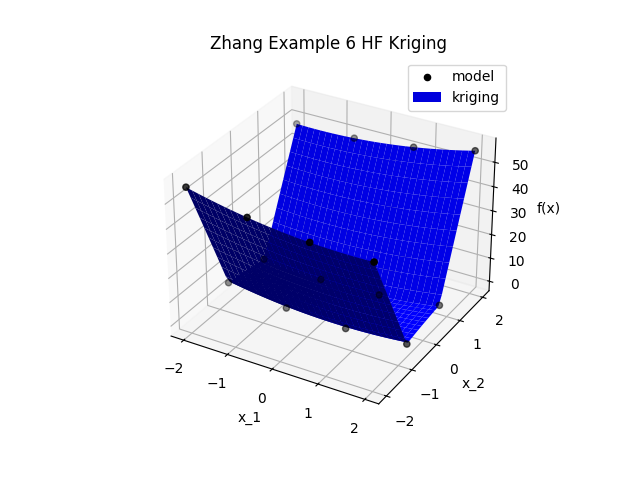

In [10]:
# Try running the hf data in a kriging model and plot the results
from SurrogateModels import kriging

zhang_example6_kriging = kriging.Kriging(x_hf, y_hf)
ax = zhang_example6_kriging.plot_data(name="Zhang Example 6 HF Fit")

ax = zhang_example6_kriging.plot_model(
    mf_2d.bounds,
    name="Zhang Example 6 HF Kriging",
    color="blue",
    label="kriging",
    ax=ax,
    n_samples=30,
)

# X1, X2 = mff.generate_grid(x1min, x1max, x2min, x2max, n_samp)
# y_samp = zhang_example6_kriging.evaluate(x_samp)
# y_samp = y_samp.reshape(n_samp,n_samp)

# ax.plot_surface(X1, X2, y_samp,label="kriging surface")
# ax.legend()
plt.show()

C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:91: RuntimeWarning: divide by zero encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\scipy\optimize\_numdiff.py:592: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0
C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\mf_model.py:46: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


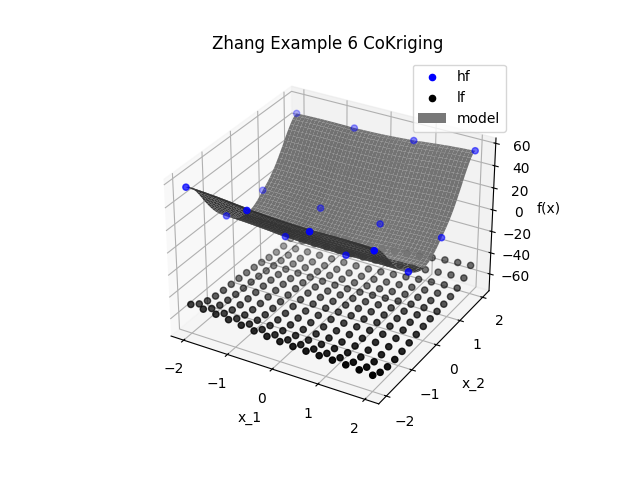

In [11]:
# Cokriging model for zhang example 6
from SurrogateModels import cokriging

zhang_example6_cokriging = cokriging.CoKriging(x_lf, y_lf, x_hf, y_hf)
plot_name = "Zhang Example 6 CoKriging"
ax = zhang_example6_cokriging.plot_data(name=plot_name)

zhang_example6_cokriging.plot_model(mf_2d.bounds,name=plot_name,color="gray",ax=ax,n_samples=50)

ax.legend()
plt.show()

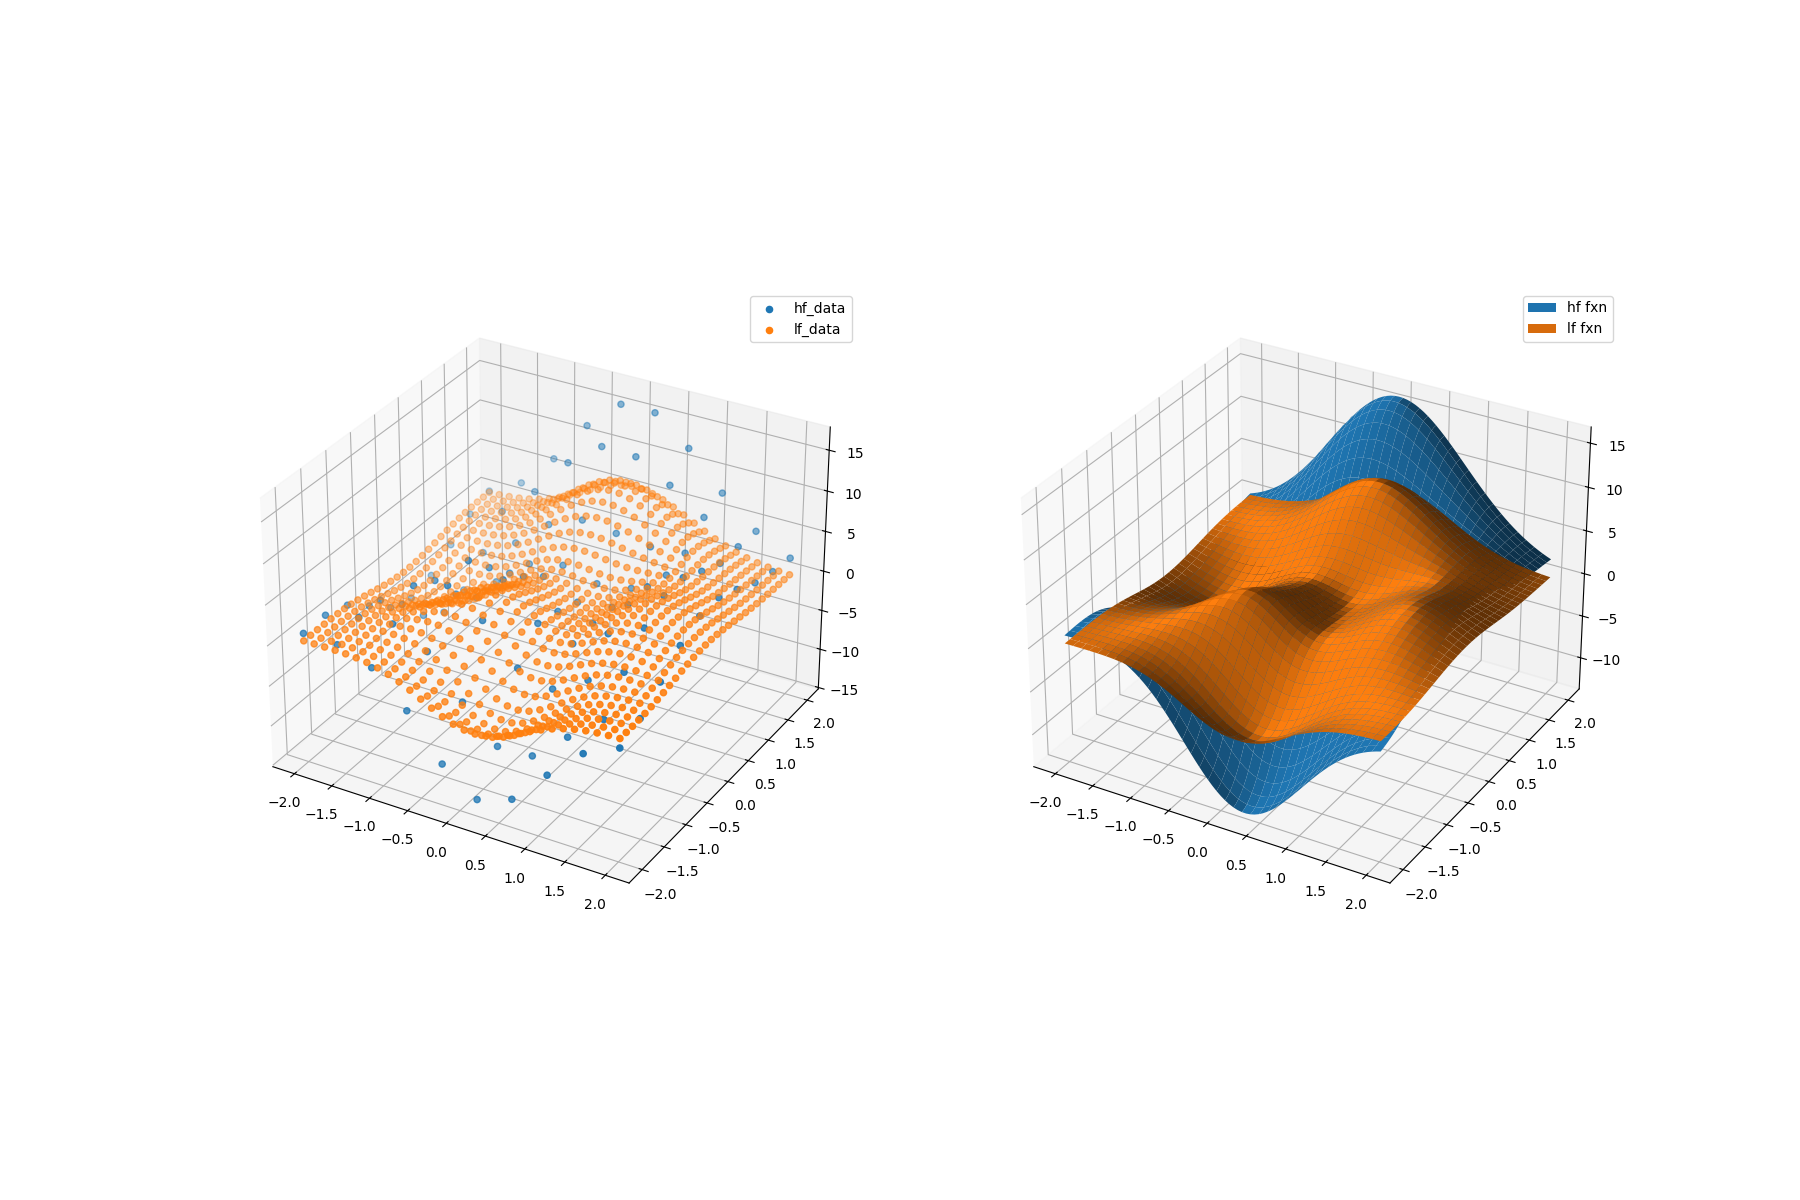

In [12]:
import multi_fidelity_functions as mff
import matplotlib.pyplot as plt
from SurrogateModels import cokriging, model

n_hf = 10
n_lf = 30
n_samp = 75

mf_2d = mff.PeaksShifted()

bounds = mf_2d.bounds
x1min = bounds[0][0]
x1max = bounds[0][1]
x2min = bounds[1][0]
x2max = bounds[1][1]

x_hf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_hf)
x_lf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_lf)
y_hf = mf_2d.high_fidelity(x_hf)
y_lf = mf_2d.low_fidelity(x_lf)

# take samples for plotting ground truth function
x_samp = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = mf_2d.high_fidelity(x_samp)
y_samp_lf = mf_2d.low_fidelity(x_samp)

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(121, projection="3d")

sc = ax.scatter(x_hf[:, 0], x_hf[:, 1],y_hf[:,0], label="hf_data")
sc = ax.scatter(x_lf[:, 0], x_lf[:, 1],y_lf[:,0], label="lf_data")
ax.legend()

#Plot the actual surfaces of the lf and hf functions

X1, X2 = model.Model.generate_grid(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = y_samp_hf.reshape(n_samp,n_samp)
y_samp_lf = y_samp_lf.reshape(n_samp,n_samp)

ax = fig.add_subplot(122, projection="3d")
ax.plot_surface(X1, X2, y_samp_hf,label="hf fxn")
ax.plot_surface(X1, X2, y_samp_lf,label="lf fxn")
ax.legend()

plt.show()

c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\numpy\linalg\linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:199: RuntimeWarning: divide by zero encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))


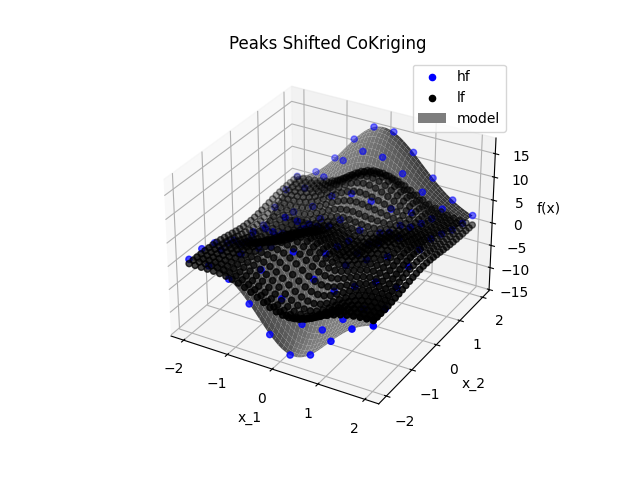

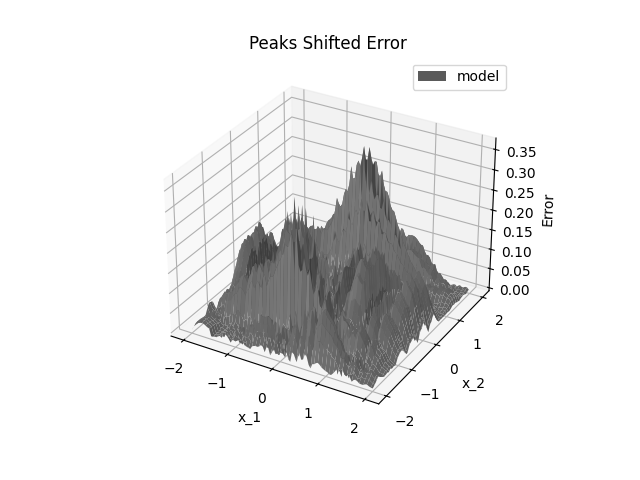

In [13]:
# Cokriging model for zhang example 6
from SurrogateModels import cokriging

peaks_shifted_cokriging = cokriging.CoKriging(x_lf, y_lf, x_hf, y_hf)
plot_name = "Peaks Shifted CoKriging"
ax = peaks_shifted_cokriging.plot_data(name=plot_name)

peaks_shifted_cokriging.plot_model(
    mf_2d.bounds, name=plot_name, color="gray", ax=ax, n_samples=50
)


ax.legend()
plt.show()

peaks_shifted_cokriging.plot_rms_error(
    mf_2d.bounds, mf_2d.high_fidelity, name="Peaks Shifted Error", color="gray"
)
plt.show()

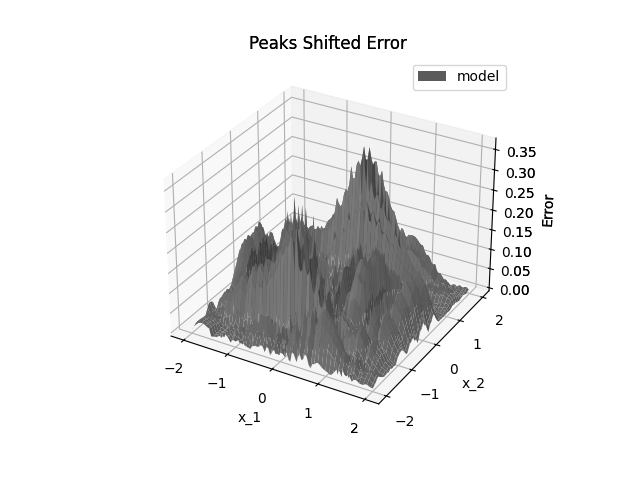

In [14]:
ax = peaks_shifted_cokriging.plot_rms_error(
    mf_2d.bounds, mf_2d.high_fidelity, name="Peaks Shifted Error", color="gray"
)
#ax.set_zlim(-0.01,0.02)
plt.show()